<h1><center> Les modèles statistiques traditionnels (ARIMA & friends)

### 1. Génération du jeu de données

In [33]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt


In [34]:
np.random.seed(42)

n= 84           # --> 7 ans c-à-d 12 mois * 7 = 84 mois

time = np.arange(n)

# Simulation d'un processus ARIMA(1,1,1) simple
# Tendance linéaire + mémoire AR/MA
trend_component = 0.5 * time
noise = np.random.normal(0,2,n)
series = np.zeros(n)

for i in range(1,n):
    series[i] = series[i-1] + 0.6 * (series[i-1] - series[i-2]) if i > 1 else series[i] + noise[i]

series = series + trend_component + 50


# Création du dataframe
dates = pd.date_range(start="2019-01-01", periods= n, freq= "ME")
df = pd.DataFrame(
    {"Visiteurs": series},
    index= dates
)

df

,Visiteurs
2019-01-31,50.000000
2019-02-28,50.223471
2019-03-31,50.557554
2019-04-30,50.958004
2019-05-31,51.398274
...,...
2025-08-31,88.808678
2025-09-30,89.308678
2025-10-31,89.808678
2025-11-30,90.308678


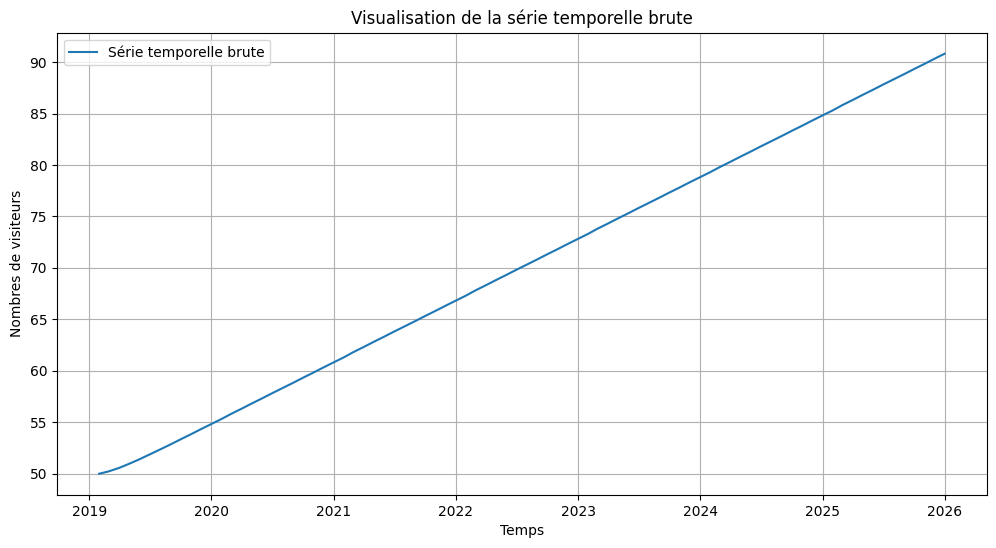

On remarque une augmentation accrue des nombres de visiteurs de 2019 à 2026


In [35]:
# Visualisation de la série temporelle brute

plt.figure(figsize=(12, 6))
plt.plot(df.index, df["Visiteurs"], label= "Série temporelle brute")
plt.xlabel("Temps")
plt.ylabel("Nombres de visiteurs")
plt.title("Visualisation de la série temporelle brute")
plt.legend()
plt.grid(True)
plt.show()

print("On remarque une augmentation accrue des nombres de visiteurs de 2019 à 2026")

### 2. Recherche automatique des hyperparamétres avec pmdarima

In [ ]:
from pmdarima import auto_arima

model = auto_arima(df["Visiteurs"], 
                start_p=1, start_q=1,  # Les valeurs de départ de la recherche de p et q
                max_p=3, max_q=3,  # Les valeurs limites de p et q (pour éviter overffitiing et economiser le temps de calcul)
                d=None,           # on laisse l'algorithme deviner le d optimal (éxécute automatiquement tests ststatistiques et test ADF)
                seasonal=False,   # Pas de saisonnalité complexe 
                trace=True,  # afficher les logs pour comprendre ce qui se passe sous le capot
                error_action='ignore', # Si une combinaison de valeurs pdq pante, ne fais pas tout planter, ignore-le et passe au suivant
                suppress_warnings=True, # masque les messages d'avertissement
                stepwise=True) # VOIR EN BAS


Performing stepwise search to minimize aic
 ARIMA(1,2,1)(0,0,0)[0] intercept   : AIC=-277.386, Time=0.17 sec
 ARIMA(0,2,0)(0,0,0)[0] intercept   : AIC=-453.234, Time=0.13 sec
 ARIMA(1,2,0)(0,0,0)[0] intercept   : AIC=-279.386, Time=0.08 sec
 ARIMA(0,2,1)(0,0,0)[0] intercept   : AIC=-438.205, Time=0.08 sec
 ARIMA(0,2,0)(0,0,0)[0]             : AIC=-451.134, Time=0.05 sec

Best model:  ARIMA(0,2,0)(0,0,0)[0] intercept
Total fit time: 0.547 seconds


<hr><hr><hr>
<b> stepwise= True </b>:

Si  testes toutes les combinaisons possibles de p, d, q de manière exhaustive:
- de 0 à 3 pour p, 
- de 0 à 2 pour d, 
- de 0 à 3 pour q, etc. 

cela fait énormément de modèles à calculer. 

Le mode stepwise=True utilise un algorithme intelligent (l'algorithme Hyndman-Khandakar) qui explore les pistes par étapes successives de manière maline pour trouver le meilleur modèle beaucoup plus rapidement, sans avoir à tester toutes les combinaisons un par un.

<hr>
Pour ces résultats, la notation générale d'un modèle est sous la forme :


<center><b>ARIMA(p, d, q)(P, D, Q)[s]</b></center>

- Les trois premiers chiffres entre les premières parenthèses correspondent à (p, d, q).
- Les trois chiffres suivants entre la deuxième parenthèse (0,0,0)[0] correspondent à la partie <b><u>saisonnière</u></b> (P, D, Q)_s. 
Comme ils sont à zéro, cela confirme qu'il n'y a pas de saisonnalité détectée ou gérée ici.
<hr>

Selon ces résultas, le meilleur modèle est :

<center><b>Best model:  ARIMA(0,2,0)(0,0,0)[0] intercept</b></center>

Cela signifie que :

- p= 0 (pas de terme autorégressif, on n'a pas besoin de regader les valeurs passées de la série)

- d= 2 (La série a été différenciée 2 fois pour devenir stationnaire)

- q= 0 (Pas de terme de moyenne mobile, pas de mémoire sur les chocs passés)

- intrcept: veut dire que lo mod_le a inclus une constante

### 3. Analyse du modèle:

In [37]:
print(model.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                   84
Model:               SARIMAX(0, 2, 0)   Log Likelihood                 228.617
Date:                Sun, 18 Oct 2026   AIC                           -453.234
Time:                        19:19:29   BIC                           -448.421
Sample:                    01-31-2019   HQIC                          -451.302
                         - 12-31-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.0034      0.005      0.672      0.502      -0.006       0.013
sigma2         0.0002   2.48e-05      8.928      0.000       0.000       0.000
Ljung-Box (L1) (Q):                  30.55   Jarque-

### 3. Demander au modèle de prédire les 12 prochains mois (soit l'année 2026)

In [ ]:
forecast, confint = model.predict(periods= 12, return_conf_int=True) # return_conf_int=True (qui renvoie confint) sert à récupérer l'intervalle de confiance de la prévision.
forecast

2026-01-31    91.312050
2026-02-28    91.818794
2026-03-31    92.328910
2026-04-30    92.842398
2026-05-31    93.359257
2026-06-30    93.879489
2026-07-31    94.403092
2026-08-31    94.930067
2026-09-30    95.460414
2026-10-31    95.994134
Freq: ME, dtype: float64

In [43]:
confint

array([[91.28286379, 91.34123702],
       [91.75353098, 91.88405748],
       [92.21970365, 92.43811627],
       [92.68253594, 93.00225927],
       [93.14280344, 93.57571087],
       [93.60106608, 94.15791117],
       [94.05775134, 94.74843267],
       [94.51319907, 95.34693551],
       [94.96768775, 95.95314123],
       [95.4214509 , 96.5668163 ],
       [95.874688  , 97.18776125],
       [96.32757201, 97.8158031 ]])

In [39]:
# on crée un index temporel pour les prédictions
forecast_dates = pd.date_range(start= "2026-01-01", periods= 12, freq= "ME")

forecast_series = pd.Series(forecast, index= forecast_dates)
forecast_series

2026-01-31    91.312050
2026-02-28    91.818794
2026-03-31    92.328910
2026-04-30    92.842398
2026-05-31    93.359257
2026-06-30    93.879489
2026-07-31    94.403092
2026-08-31    94.930067
2026-09-30    95.460414
2026-10-31    95.994134
2026-11-30          NaN
2026-12-31          NaN
Freq: ME, dtype: float64

### 5. Visualisation de l'historique et des prévisions

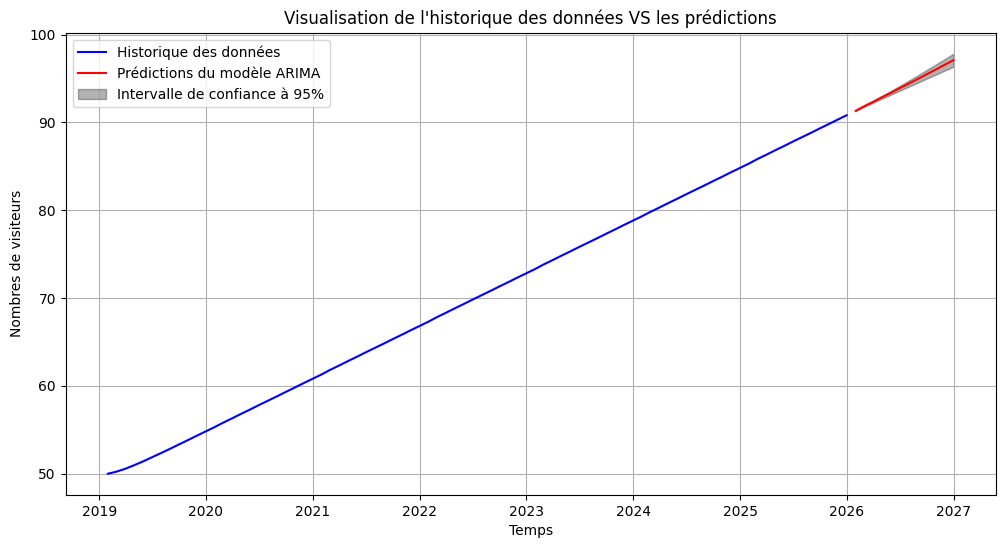

In [50]:
plt.figure(figsize=(12, 6))
plt.plot(df.index, df["Visiteurs"], label= "Historique des données", color= "blue")
plt.plot(forecast_series.index, forecast_series, label = "Prédictions du modèle ARIMA", color= "Red")

# Ajout de l'intervalle de confiance OPTIONNEL
plt.fill_between(forecast_dates, 
                 confint[:, 0], # Borne inférieure
                 confint[:, 1], # Borne supérieure
                 color="black", alpha=0.3, label="Intervalle de confiance à 95%")

plt.xlabel("Temps")
plt.ylabel("Nombres de visiteurs")
plt.title("Visualisation de l'historique des données VS les prédictions")
plt.legend()
plt.grid(True)
plt.show()